# 第 2 章 概率分布及其用途 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 2 章（§2.1–2.10）。

13 个实验对应五大抽样技术 + 八大分布，输出图 `out-2-M.png`（M=实验号）。随机种子 2025。

In [1]:
# ===== 公共设置 =====
import numpy as np
import math
import matplotlib.pyplot as plt
from pathlib import Path

rng = np.random.default_rng(2025)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch02")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 离散 cdf 反演 + 重排序加速（书 §2.1.2，Alg 2.1）

岸鸟产卵数 Pr(2,3,4,5)=0.15,0.20,0.60,0.05。对比原序/按概率降序两种断点排布的**平均循环次数**（书：2.55 → 1.65）。

原序     平均循环 2.545 次（书 2.55）
降序重排 平均循环 1.652 次（书 1.65）
频率 vs 目标: [0.15236 0.19985 0.59814 0.04965] vs [0.15 0.2  0.6  0.05]


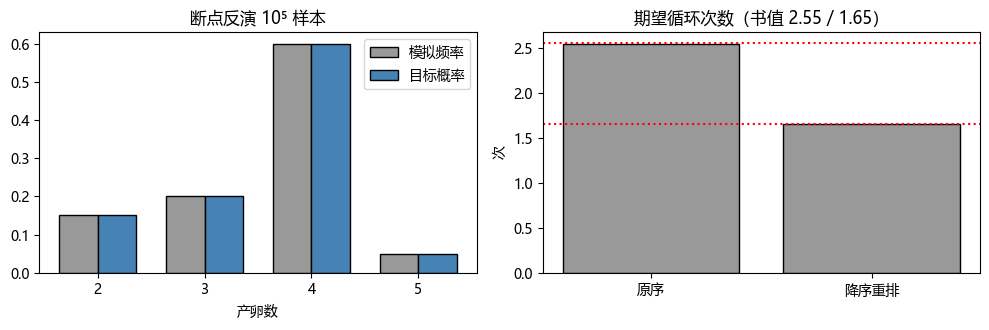

In [2]:
# ===== 书 §2.1.2 Alg 2.1 =====
oc = np.array([2, 3, 4, 5])
op = np.array([0.15, 0.2, 0.6, 0.05])

def make_bp(probs):
    return np.cumsum(probs)                       # bp[i] = bp[i-1] + op[i]

def sample_once(bp, outcomes, r=rng):
    U = r.random(); k = 0
    while U >= bp[k]:
        k += 1
    return outcomes[k], k+1                       # 返回样本与循环次数

N = 100_000
bp1 = make_bp(op)
samp1, loops1 = zip(*(sample_once(bp1, oc) for _ in range(N)))
counts1 = np.bincount(samp1, minlength=6)[2:6]

# 重排序：按概率降序
order = np.argsort(-op)
oc2, op2 = oc[order], op[order]
bp2 = make_bp(op2)
samp2, loops2 = zip(*(sample_once(bp2, oc2) for _ in range(N)))
counts2 = np.zeros(4, dtype=int)
for s in samp2: counts2[oc.index(s) if False else list(oc).index(s)] += 1

print(f"原序     平均循环 {np.mean(loops1):.3f} 次（书 2.55）")
print(f"降序重排 平均循环 {np.mean(loops2):.3f} 次（书 1.65）")
print(f"频率 vs 目标: {counts1/N} vs {op}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(4)
ax[0].bar(x-0.18, counts1/N, 0.36, label="模拟频率", color="0.6", edgecolor="k")
ax[0].bar(x+0.18, op, 0.36, label="目标概率", color="steelblue", edgecolor="k")
ax[0].set_xticks(x, ["2","3","4","5"])
ax[0].set_title("断点反演 10⁵ 样本"); ax[0].legend(); ax[0].set_xlabel("产卵数")
ax[1].bar(["原序", "降序重排"], [np.mean(loops1), np.mean(loops2)],
          color="0.6", edgecolor="k")
ax[1].axhline(2.55, ls=":", color="r"); ax[1].axhline(1.65, ls=":", color="r")
ax[1].set_title("期望循环次数（书值 2.55 / 1.65）"); ax[1].set_ylabel("次")
plt.tight_layout(); save(fig, "out-2-1.png"); plt.show()

## 实验 2 Walker alias：构造与验收（书 §2.2，Alg 2.4）

一窝 8 只雌雏数分布（Table 2.1），构造 Q、A 两表应与书逐项一致：Q=[0.18,0.36,0.72,0.53,0.88,0.56,1.0,0.81,0.45]，A=[4,5,5,6,6,7,−,6,6]。

Q 误差 vs 书（数值序列）: [ 0.  0.  0.  0.  0.  0.  0. -0.  0.]
A vs 书−1             : [ 3  4  4  5  5  6 -1  5  5] vs [ 3  4  4  5  5  6 -1  5  5]


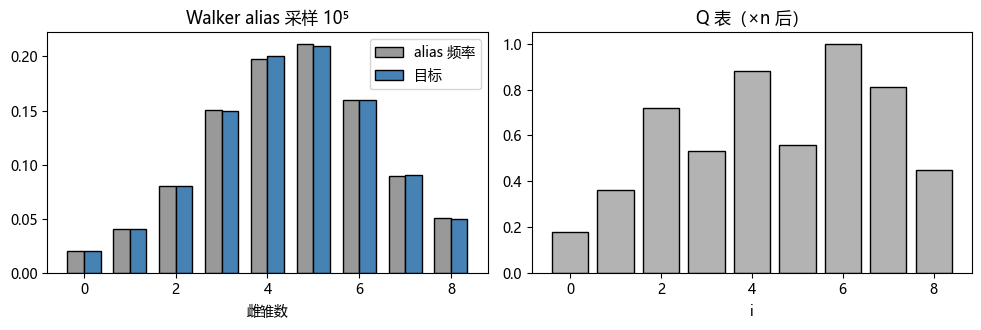

最大频率偏差 = 0.0021


In [3]:
# ===== 书 §2.2 Alg 2.4 Walker 构造 =====
rw = np.array([.02, .04, .08, .15, .2, .21, .16, .09, .05])
n = len(rw)
tab = rw.copy()
Q = np.zeros(n); A = np.full(n, -1)
S = 1.0 / n

for _ in range(n-1):                       # 每轮钉死一个扇区
    t = next(i for i in range(n) if 0 < tab[i] <= S)   # 不足者
    p = next(i for i in range(n) if tab[i] > S)        # 超额者
    Q[t] = tab[t]
    A[t] = p
    residual = S - Q[t]                    # p 支付的缺口
    tab[t] = 0.0
    tab[p] -= residual
t_last = int(np.argmax(tab)); Q[t_last] = tab[t_last]  # 最后一个
Q = np.maximum(Q, 0); tab = np.maximum(tab, 0)  # 浮点残差钳零
Q *= n                                       # 乘 n（书步骤：均匀扇区被选概率 1/n）

# 书正文用 1 基下标（t=1↔0 基的 0）；数值序列应逐项一致，A 为书值 −1
Q_book = np.array([0.18,0.36,0.72,0.53,0.88,0.56,1.0,0.81,0.45])
A_book = np.array([4,5,5,6,6,7,-1,6,6])
print("Q 误差 vs 书（数值序列）:", np.round(Q - Q_book, 4))
print("A vs 书−1             :", A, "vs", np.where(A_book<0, -1, A_book-1))

# 采样验收
def alias_sample(r=rng):
    # 书印 "if Q[Y] < Z return Y" 与其构造矛盾（Q=1 的满扇区 A 为 "-" 却被访问）；
    # 正确判据是 Z < Q[Y]：Y 以 Q[Y]/n 概率自留，否则转别名 A[Y]。
    U = r.random()*n
    Y, Z = int(U), U - int(U)
    if Z < Q[Y]: return Y
    return int(A[Y]) if A[Y] >= 0 else Y

Ns = 100_000
freq = np.bincount([alias_sample() for _ in range(Ns)], minlength=n)/Ns
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(n)
ax[0].bar(x-0.18, freq, 0.36, label="alias 频率", color="0.6", edgecolor="k")
ax[0].bar(x+0.18, rw, 0.36, label="目标", color="steelblue", edgecolor="k")
ax[0].set_xlabel("雌雏数"); ax[0].set_title("Walker alias 采样 10⁵"); ax[0].legend()
ax[1].bar(x, Q, color="0.7", edgecolor="k")
ax[1].set_title("Q 表（×n 后）"); ax[1].set_xlabel("i")
plt.tight_layout(); save(fig, "out-2-2.png"); plt.show()
print(f"最大频率偏差 = {np.abs(freq-rw).max():.4f}")

## 实验 3 二项分布两法抽样（书 §2.3）

$b(20, 18/38)$：伯努利重复模拟 vs NumPy API，叠加精确 pmf；验证 $\mu=np$、var $=npq$。

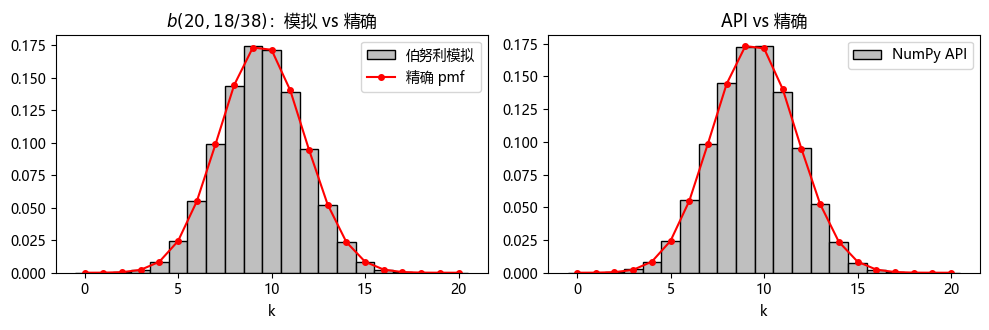

均值: 模拟 9.471 vs np=9.474；方差: 4.973 vs npq=4.986


In [4]:
# ===== 书 §2.3 二项 =====
n, p = 20, 18/38
q = 1-p
# 法一：n 次伯努利重复（模拟）
sims = (rng.random((100_000, n)) < p).sum(axis=1)
# 法二：API
api = rng.binomial(n, p, 100_000)
ks = np.arange(n+1)
pmf = np.array([math.comb(n, k)*p**k*q**(n-k) for k in ks])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(sims, bins=np.arange(-0.5, n+1.5), density=True,
           color="0.75", edgecolor="k", label="伯努利模拟")
ax[0].plot(ks, pmf, "ro-", ms=4, label="精确 pmf")
ax[0].set_title(r"$b(20,18/38)$：模拟 vs 精确"); ax[0].set_xlabel("k"); ax[0].legend()
ax[1].hist(api, bins=np.arange(-0.5, n+1.5), density=True,
           color="0.75", edgecolor="k", label="NumPy API")
ax[1].plot(ks, pmf, "ro-", ms=4)
ax[1].set_title("API vs 精确"); ax[1].set_xlabel("k"); ax[1].legend()
plt.tight_layout(); save(fig, "out-2-3.png"); plt.show()
print(f"均值: 模拟 {sims.mean():.3f} vs np={n*p:.3f}；方差: {sims.var():.3f} vs npq={n*p*q:.3f}")

## 实验 4 泊松：乘积法 + 二项近似三路（书 §2.4，Alg 2.5；习题 13）

$\lambda t=3$。左：乘积法 $\prod U_i>e^{-\lambda t}$。右：$b(20,\lambda t/20),b(60,\cdot),b(100,\cdot)$ 逼近泊松。

乘积法泊松: 均值 3.008, 方差 3.029（理论均 = 3.0）


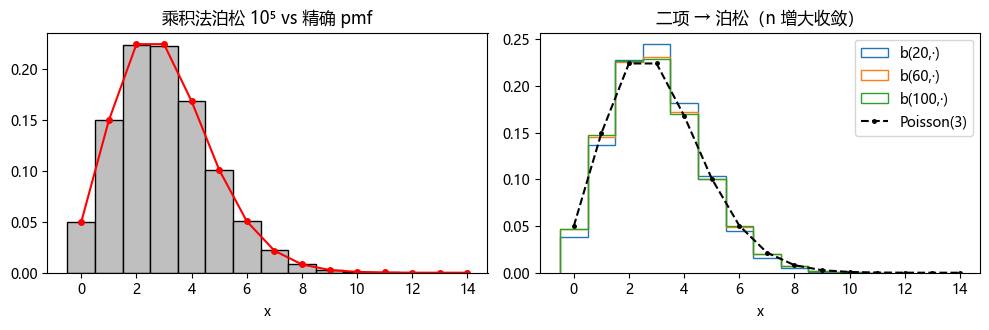

In [5]:
# ===== 书 §2.4 Alg 2.5 泊松 =====
lamt = 3.0; targ = np.exp(-lamt)

def poisson_prod(r=rng):
    u, x = 1.0, 0
    while True:
        u *= r.random()
        if u < targ: return x
        x += 1

pois = np.array([poisson_prod() for _ in range(100_000)])
ks = np.arange(15)
pois_pmf = lamt**ks*np.exp(-lamt)/np.array([math.factorial(k) for k in ks])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(pois, bins=np.arange(-0.5, 12.5), density=True, color="0.75", edgecolor="k")
ax[0].plot(ks, pois_pmf, "ro-", ms=4)
ax[0].set_title("乘积法泊松 10⁵ vs 精确 pmf"); ax[0].set_xlabel("x")
print(f"乘积法泊松: 均值 {pois.mean():.3f}, 方差 {pois.var():.3f}（理论均 = {lamt}）")

for nb_ in (20, 60, 100):
    approx = rng.binomial(nb_, lamt/nb_, 100_000)
    ax[1].hist(approx, bins=np.arange(-0.5, 12.5), density=True,
               histtype="step", lw=1.6, label=f"b({nb_},·)")
ax[1].plot(ks, pois_pmf, "k.--", ms=5, label="Poisson(3)")
ax[1].set_title("二项 → 泊松（n 增大收敛）"); ax[1].set_xlabel("x"); ax[1].legend()
plt.tight_layout(); save(fig, "out-2-4.png"); plt.show()

## 实验 5 指数：cdf 反演 + 无记忆性实测（书 §2.5）

$W=-\ln(1-U)/\lambda$。无记忆性：$\Pr(W>a+b\mid W\ge a)=\Pr(W>b)$ 用模拟直接验证。

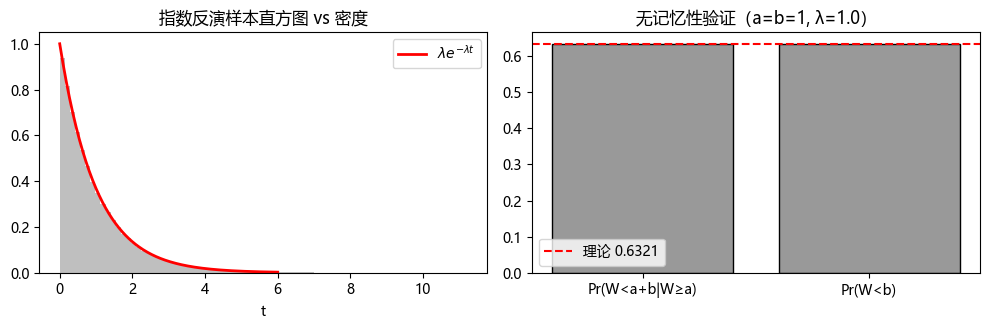

均值 0.9958（理论 1/λ=1），方差 0.9987（理论 1）


In [6]:
# ===== 书 §2.5 指数 =====
lam = 1.0
U = rng.random(200_000)
W = -np.log(1-U)/lam                    # 规范反演

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
t = np.linspace(0, 6, 200)
ax[0].hist(W, bins=80, density=True, color="0.75", edgecolor="none")
ax[0].plot(t, lam*np.exp(-lam*t), "r-", lw=2, label=r"$\lambda e^{-\lambda t}$")
ax[0].set_title("指数反演样本直方图 vs 密度"); ax[0].set_xlabel("t"); ax[0].legend()

# 无记忆性：a=1, b=1
a, b = 1.0, 1.0
lhs = np.mean(W[(W >= a)] < a + b)      # P(W<a+b | W>=a)
rhs = np.mean(W < b)                    # P(W<b)
ax[1].bar(["Pr(W<a+b|W≥a)", "Pr(W<b)"], [lhs, rhs], color="0.6", edgecolor="k")
ax[1].axhline(1-np.exp(-lam*b), ls="--", color="r",
              label=f"理论 {1-np.exp(-lam*b):.4f}")
ax[1].set_title(f"无记忆性验证（a=b=1, λ={lam}）"); ax[1].legend()
plt.tight_layout(); save(fig, "out-2-5.png"); plt.show()
print(f"均值 {W.mean():.4f}（理论 1/λ=1），方差 {W.var():.4f}（理论 1）")

## 实验 6 柯西：重尾与均值不收敛（书 §2.5.3）

$X=\tan(\pi(U-1/2))$。滑动均值 vs 正态的滑动均值——大数定律前提失效的活教材。

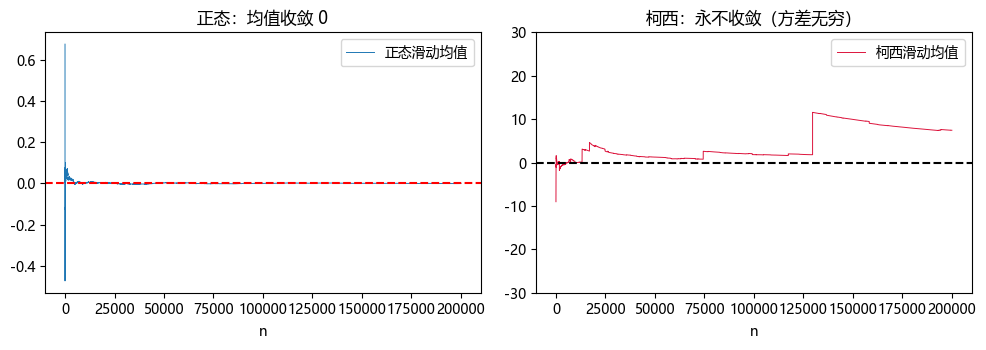

柯西样本均值（10⁵ 截断前后）: 1.25 → 7.43（每跑每样）


In [7]:
# ===== 书 §2.5.3 柯西 =====
N = 200_000
cauchy = np.tan(np.pi*(rng.random(N) - 0.5))
norma = rng.normal(size=N)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
run_c = np.cumsum(cauchy)/np.arange(1, N+1)
run_n = np.cumsum(norma)/np.arange(1, N+1)
ax[0].plot(run_n, lw=0.7, label="正态滑动均值")
ax[0].axhline(0, color="r", ls="--")
ax[0].set_title("正态：均值收敛 0"); ax[0].set_xlabel("n")
ax[1].plot(run_c, lw=0.7, color="crimson", label="柯西滑动均值")
ax[1].axhline(0, color="k", ls="--")
ax[1].set_ylim(-30, 30); ax[1].set_title("柯西：永不收敛（方差无穷）")
ax[1].set_xlabel("n")
for a_ in ax: a_.legend()
plt.tight_layout(); save(fig, "out-2-6.png"); plt.show()
print(f"柯西样本均值（10⁵ 截断前后）: {cauchy[:50_000].mean():.2f} → {cauchy.mean():.2f}（每跑每样）")

## 实验 7 正态抽样三法 + Marsaglia–Bray 拒绝率（书 §2.6.1）

CLT 法（n=12）、Box–Muller、Marsaglia–Bray 各 5 万样本叠加 $N(0,1)$ 密度；实测 MB 拒绝率 $\approx 1-\pi/4$。

CLT 法均值的绝对偏差（单次）: 0.0002
Marsaglia–Bray 拒绝率 = 0.2162（理论 1−π/4 = 0.2146）


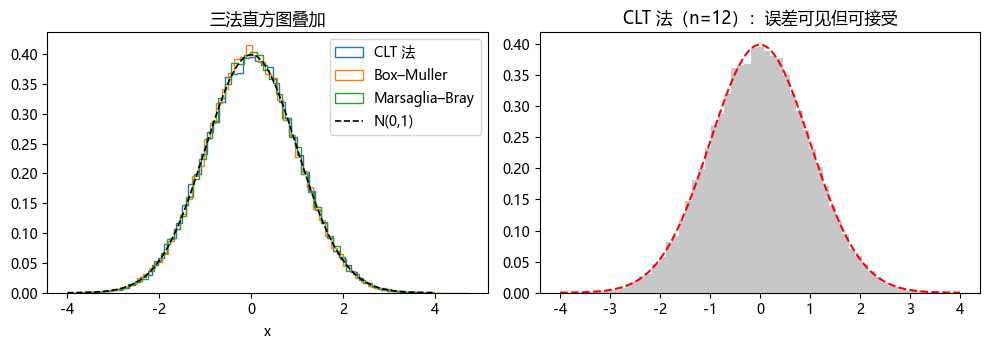

In [8]:
# ===== 书 §2.6.1 三法 =====
Nn = 50_000
# ① CLT 法
U12 = rng.random((Nn, 12))
x_clt = U12.sum(axis=1) - 6.0            # (ΣU − n/2)/√(n/12)，n=12 时分母=1
# ② Box–Muller
u1, u2 = rng.random(Nn), rng.random(Nn)
x_bm = np.cos(2*np.pi*u1)*np.sqrt(-2*np.log(u2))
# ③ Marsaglia–Bray
xs_mb, tries, acc = [], 0, 0
while len(xs_mb) < Nn:
    v = rng.random((4096, 2))*2 - 1
    s = (v**2).sum(axis=1)
    keep = s < 1
    tries += len(v); acc += keep.sum()
    if keep.any():
        r = np.sqrt(-2*np.log(s[keep])/s[keep])
        xs_mb.extend((v[keep,0]*r).tolist())
xs_mb = np.array(xs_mb[:Nn])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
t = np.linspace(-4, 4, 300)
pdfn = np.exp(-t**2/2)/np.sqrt(2*np.pi)
for dat, lab in [(x_clt, "CLT 法"), (x_bm, "Box–Muller"), (xs_mb, "Marsaglia–Bray")]:
    ax[0].hist(dat, bins=60, density=True, histtype="step", lw=1.5, label=lab)
ax[0].plot(t, pdfn, "k--", lw=1.2, label="N(0,1)")
ax[0].set_title("三法直方图叠加"); ax[0].set_xlabel("x"); ax[0].legend()
ax[1].hist(x_clt, bins=60, density=True, color="0.78", edgecolor="none")
ax[1].plot(t, pdfn, "r--", lw=1.5)
ax[1].set_title("CLT 法（n=12）：误差可见但可接受")
err12 = abs(x_clt.mean()) ; print(f"CLT 法均值的绝对偏差（单次）: {err12:.4f}")
print(f"Marsaglia–Bray 拒绝率 = {1-acc/tries:.4f}（理论 1−π/4 = {1-np.pi/4:.4f}）")
plt.tight_layout(); save(fig, "out-2-7.png"); plt.show()

## 实验 8 batching 与 Student-t 置信区间覆盖率（书 §2.6.3，式 (2.20)(2.21)）

总体 = 指数(1)，每"次模拟"出 20 批 × 50 样本，按 $t=\frac{\hat\theta-\theta}{s_B/\sqrt m}$ 造 95% 区间；重复 1000 次看覆盖率（理论 0.95）。

In [9]:
# ===== 书 §2.6.3 batching =====
from scipy import stats
m, J = 20, 50          # 批数、批大小
theta_true = 1.0       # E[Exp(1)]
cov = 0
for rep in range(1000):
    X = rng.exponential(1.0, m*J).reshape(m, J)
    B = X.mean(axis=1)                    # 批均值
    th_hat = B.mean()
    sB2 = ((B - th_hat)**2).sum()/(m-1)   # 式 (2.20)
    tcrit = stats.t.ppf(0.975, m-1)       # β=(1+0.95)/2
    half = tcrit*np.sqrt(sB2/m)
    cov += (th_hat - half <= theta_true <= th_hat + half)
print(f"95% t 区间实测覆盖率 = {cov/1000:.3f}")
# 对照：J 太小（批均值仍相关，此处独立总体的对照是名义 95% 应守住）
m2, J2 = 200, 5
cov2 = 0
for rep in range(1000):
    B = rng.exponential(1.0, (m2, J2)).mean(axis=1)
    th_hat = B.mean(); sB2 = ((B-th_hat)**2).sum()/(m2-1)
    half = stats.t.ppf(0.975, m2-1)*np.sqrt(sB2/m2)
    cov2 += (th_hat-half <= theta_true <= th_hat+half)
print(f"m=200, J=5 覆盖率 = {cov2/1000:.3f}（区间更窄，覆盖率仍近名义）")

95% t 区间实测覆盖率 = 0.959
m=200, J=5 覆盖率 = 0.950（区间更窄，覆盖率仍近名义）


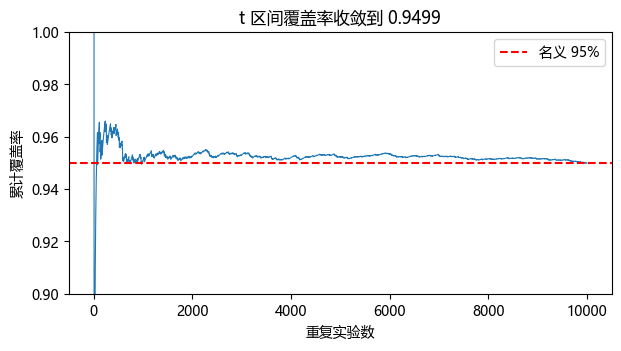

In [10]:
# 覆盖率可视化（10⁴ 次重复，m=20, J=50）
covs = []
for rep in range(10_000):
    B = rng.exponential(1.0, (m, J)).mean(axis=1)
    th_hat = B.mean(); sB2 = ((B-th_hat)**2).sum()/(m-1)
    half = stats.t.ppf(0.975, m-1)*np.sqrt(sB2/m)
    covs.append(th_hat-half <= theta_true <= th_hat+half)
covs = np.array(covs)
# 滑动覆盖率 + 终值
fig, ax = plt.subplots(figsize=(7, 3.4))
run = np.cumsum(covs)/np.arange(1, len(covs)+1)
ax.plot(run, lw=0.8)
ax.axhline(0.95, color="r", ls="--", label="名义 95%")
ax.set_ylim(0.90, 1.0); ax.set_xlabel("重复实验数"); ax.set_ylabel("累计覆盖率")
ax.set_title(f"t 区间覆盖率收敛到 {run[-1]:.4f}")
ax.legend(); save(fig, "out-2-8.png"); plt.show()

## 实验 9 Gibrat / 对数正态（书 §2.7，Alg 2.7 简版）

$R\sim U(0.2,2)$，$X=\prod_{i=1}^{10}R_i$ 应近似 $LN(-0.510, 1.794^2)$。

理论 α=-0.510, β=1.795（书 −0.510 / 1.794）


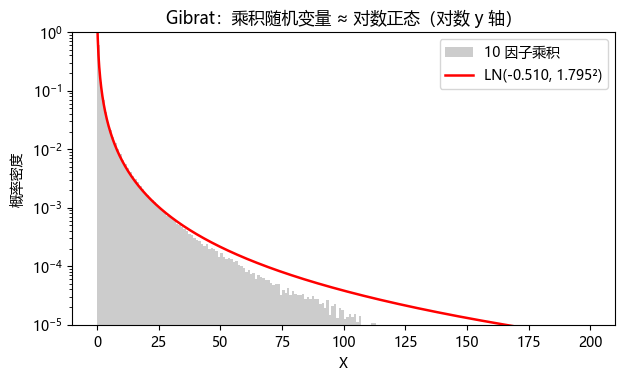

In [11]:
# ===== 书 §2.7 Gibrat =====
a, b, nfac = 0.2, 2.0, 10
c = b - a
R = a + c*rng.random((2_000_000, nfac))
X = R.prod(axis=1)
# 理论参数（书闭式）
alfa = (nfac/c)*(b*(np.log(b)-1) - a*(np.log(a)-1))
beta2 = (nfac/c)*(b*(np.log(b)**2 - 2*np.log(b) + 2)
                  - a*(np.log(a)**2 - 2*np.log(a) + 2)) - alfa**2
beta = np.sqrt(beta2)
print(f"理论 α={alfa:.3f}, β={beta:.3f}（书 −0.510 / 1.794）")

xs = np.linspace(0.05, 200, 2000)
ln_pdf = np.exp(-(np.log(xs)-alfa)**2/(2*beta2))/(xs*beta*np.sqrt(2*np.pi))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(X, bins=200, range=(0, 200), density=True, color="0.8",
        edgecolor="none", label="10 因子乘积")
ax.plot(xs, ln_pdf, "r-", lw=1.8, label=f"LN({alfa:.3f}, {beta:.3f}²)")
ax.set_yscale("log"); ax.set_ylim(1e-5, 1)
ax.set_xlabel("X"); ax.set_ylabel("概率密度")
ax.set_title("Gibrat：乘积随机变量 ≈ 对数正态（对数 y 轴）")
ax.legend(); save(fig, "out-2-9.png"); plt.show()

## 实验 10 拒绝采样 Be(2,3)（书 §2.8.2，式 (2.30)）

$f=12x(1-x)^2$，$g=U(0,1)$，$M=16/9$，$h=\frac{27}{4}x(1-x)^2$。实测接受率应 ≈ $1/M=9/16$。

接受率 = 0.5610（理论 1/M = 0.5625）


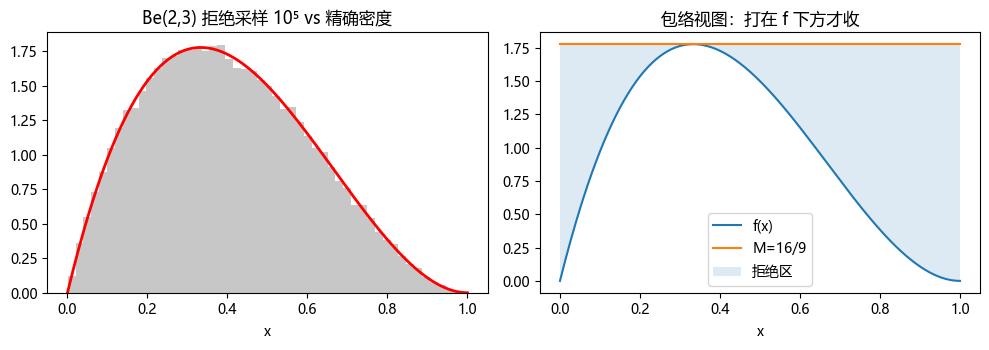

In [12]:
# ===== 书 §2.8.2 Be(2,3) =====
def f23(x): return 12*x*(1-x)**2
M = 16/9
def beta23_sample(r=rng):
    while True:
        U = r.random()
        if r.random() < (27/4)*U*(1-U)**2:    # h(U)
            return U
Nacc = 0; draws = 0; samples = []
while len(samples) < 100_000:
    draws += 1
    U = rng.random()
    Nacc += 1
    if rng.random() < (27/4)*U*(1-U)**2:
        samples.append(U)
samples = np.array(samples)
print(f"接受率 = {len(samples)/draws:.4f}（理论 1/M = {1/M:.4f}）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xs = np.linspace(0, 1, 300)
ax[0].hist(samples, bins=50, density=True, color="0.78", edgecolor="none")
ax[0].plot(xs, f23(xs), "r-", lw=2)
ax[0].set_title("Be(2,3) 拒绝采样 10⁵ vs 精确密度"); ax[0].set_xlabel("x")
ax[1].plot(xs, f23(xs), label="f(x)")
ax[1].plot(xs, M*np.ones_like(xs), label="M=16/9")
ax[1].fill_between(xs, f23(xs), M, alpha=0.15, label="拒绝区")
ax[1].set_title("包络视图：打在 f 下方才收"); ax[1].legend(); ax[1].set_xlabel("x")
plt.tight_layout(); save(fig, "out-2-10.png"); plt.show()

## 实验 11 无界 beta Be(0.5,0.5)（书 §2.8.3）

复合提案（半区 $Y=\frac12U^{1/\alpha}$）+ 拒绝（$h=(2(1-x))^{\alpha-1}$）+ 对称反射。

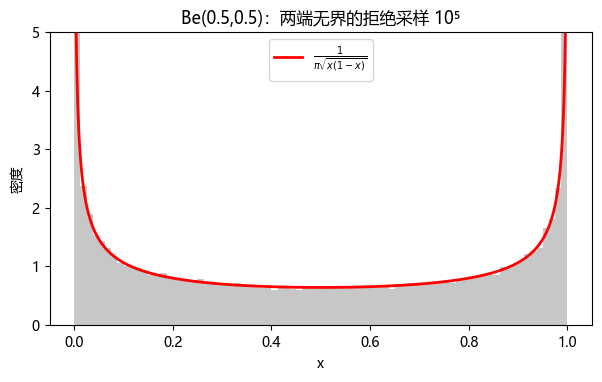

样本均值 0.4977（理论 0.5）


In [13]:
# ===== 书 §2.8.3 无界 beta =====
alpha = 0.5
def beta_half_sample(r=rng):
    while True:
        Y = 0.5*r.random()**(1/alpha)
        if r.random() < (2*(1-Y))**(alpha-1):
            return Y
def beta_asym(r=rng):
    Y = beta_half_sample(r)
    return Y if r.random() < 0.5 else 1-Y

samples = np.array([beta_asym() for _ in range(100_000)])
xs = np.linspace(1e-4, 1-1e-4, 1000)
pdf = 1/(np.pi*np.sqrt(xs*(1-xs)))       # Be(1/2,1/2) = arcsine
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(samples, bins=80, range=(0,1), density=True, color="0.78")
ax.plot(xs, pdf, "r-", lw=2, label=r"$\frac{1}{\pi\sqrt{x(1-x)}}$")
ax.set_title(r"Be(0.5,0.5)：两端无界的拒绝采样 10⁵")
ax.set_xlabel("x"); ax.set_ylabel("密度"); ax.set_ylim(0, 5); ax.legend()
save(fig, "out-2-11.png"); plt.show()
print(f"样本均值 {samples.mean():.4f}（理论 0.5）")

## 实验 12 gamma：$G(0.5,1)$ 缝合法 + Erlang $G(3,1)$ + 拼装 $G(3.5,1)$（书 §2.9.2）

$\alpha<1$：$p=e/(e+\alpha)$ 分段 + 接受；整数：$-\ln\prod U$；拼装：整数 + 小数部分。

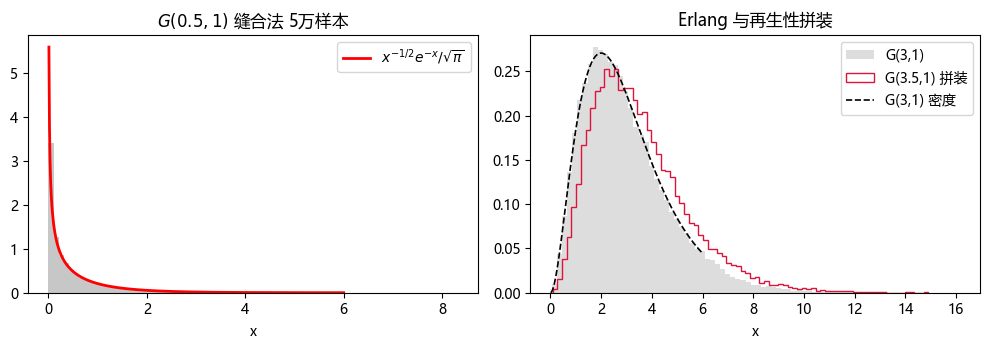

G(0.5,1) 均值 0.496（理论 0.5）；G(3,1) 均值 2.985（理论 3）


In [14]:
# ===== 书 §2.9.2 gamma =====
def gamma_small(alpha, r=rng):            # 0<α<1：复合+拒绝
    p = np.e/(np.e + alpha)
    while True:
        U1, U2 = r.random(), r.random()
        if U1 < p: Y = U2**(1/alpha)
        else:      Y = 1 - np.log(U2)
        R = r.random()
        if (Y < 1 and R < np.exp(-Y)) or (Y >= 1 and R < Y**(alpha-1)):
            return Y

def gamma_erlang(m, r=rng):               # 整 α：-ln∏U
    return -np.log(r.random(m)).sum()

s05 = np.array([gamma_small(0.5) for _ in range(50_000)])
s3 = np.array([gamma_erlang(3) for _ in range(50_000)])
s35 = s3[:25_000] + np.array([gamma_small(0.5) for _ in range(25_000)])  # 再生性拼装

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xs = np.linspace(0.01, 6, 500)
ax[0].hist(s05, bins=80, density=True, color="0.78")
ax[0].plot(xs, xs**(-0.5)*np.exp(-xs)/np.sqrt(np.pi), "r-", lw=2, label=r"$x^{-1/2}e^{-x}/\sqrt{\pi}$")
ax[0].set_title(r"$G(0.5,1)$ 缝合法 5万样本"); ax[0].set_xlabel("x"); ax[0].legend()
ax[1].hist(s3, bins=80, density=True, color="0.78", alpha=0.6, label="G(3,1)")
ax[1].hist(s35, bins=80, density=True, histtype="step", lw=1.8, color="crimson", label="G(3.5,1) 拼装")
ax[1].plot(xs, xs**2*np.exp(-xs)/2, "k--", lw=1.2, label="G(3,1) 密度")
ax[1].set_title("Erlang 与再生性拼装"); ax[1].set_xlabel("x"); ax[1].legend()
plt.tight_layout(); save(fig, "out-2-12.png"); plt.show()
print(f"G(0.5,1) 均值 {s05.mean():.3f}（理论 0.5）；G(3,1) 均值 {s3.mean():.3f}（理论 3）")

## 实验 13 三角形联合分布（书 §2.10，Alg 2.8）

$X=1-\sqrt{U_1},\ Y=U_2\sqrt{U_1}$；验证 $X$ 边缘 $=2(1-x)$、$Y|X$ 均匀。

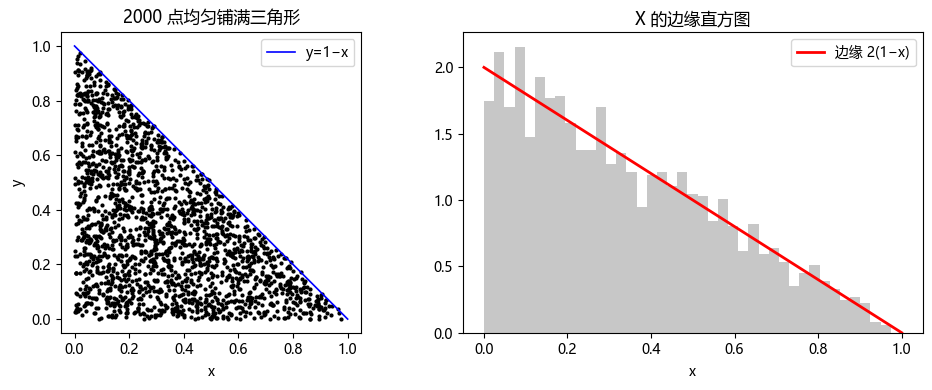

In [15]:
# ===== 书 §2.10 联合 =====
N = 2000
U1, U2 = rng.random(N), rng.random(N)
X = 1 - np.sqrt(U1); Y = U2*np.sqrt(U1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(X, Y, s=4, color="k")
xs = np.linspace(0, 1, 50)
ax[0].plot(xs, 1-xs, "b-", lw=1.2, label="y=1−x")
ax[0].set_aspect("equal"); ax[0].set_title("2000 点均匀铺满三角形"); ax[0].legend()
ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[1].hist(X, bins=40, density=True, color="0.78", edgecolor="none")
ax[1].plot(xs, 2*(1-xs), "r-", lw=2, label="边缘 2(1−x)")
ax[1].set_title("X 的边缘直方图"); ax[1].set_xlabel("x"); ax[1].legend()
plt.tight_layout(); save(fig, "out-2-13.png"); plt.show()